In [62]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
import lib
import os
from matplotlib import pyplot as plt

In [63]:
data_path = './calib/3d'

img_bgr = cv2.imread(str(os.path.join(data_path, 'img_0001.jpg')))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

In [64]:
carpeta = os.path.join("calib", "3d")
coord_pix_fotos = np.loadtxt(os.path.join(carpeta, "detected_corners.txt"))
coord_reales_puntos = np.loadtxt(os.path.join(carpeta, "p_W_corners.txt"), delimiter=",")
print("coord reales puntos")
print(coord_reales_puntos)
print("coord pix")
print(coord_pix_fotos)

obj_points, img_points = coord_reales_puntos, coord_pix_fotos[0]

coord reales puntos
[[  0.     8.     0.  ]
 [ 10.4    8.     0.  ]
 [  0.    21.5    0.  ]
 [ 10.4   21.5    0.  ]
 [  0.    26.6  -10.95]
 [ 10.4   26.6  -10.95]
 [  0.    26.6  -24.45]
 [ 10.4   26.6  -24.45]
 [ 19.4   14.6  -10.95]
 [ 19.4   14.6  -24.45]
 [ 19.4   25.   -10.95]
 [ 19.4   25.   -24.45]]
coord pix
[[186.5 187.5 264.5 ... 280.5 496.5 300.5]
 [186.5 186.5 264.5 ... 279.5 496.5 300.5]
 [187.5 186.5 265.5 ... 279.5 496.5 300.5]
 ...
 [220.5 216.5 293.5 ... 306.5 547.5 319.5]
 [214.5 226.5 289.5 ... 313.5 542.5 327.5]
 [208.5 236.5 283.5 ... 322.5 537.5 336.5]]


In [65]:
worldPts = obj_points.T[:2,:]
videoPts = img_points.T

In [66]:
# la homografia de ejemplo ya viene dada
H = np.array([[ 1.09443793e+02,  4.28987478e+01,  5.92685821e+02],
 [ 2.45115762e+00,  2.91349288e+00,  5.41092448e+02],
 [-1.02639841e-02,  2.98016564e-02,  1.00000000e+00]])

In [67]:
# paso las coordenadas del mundo real a coordenadas homogeneas (le agrego la fila de ceros)
h_world = np.vstack([worldPts, np.ones(worldPts.shape[1])])

In [68]:
# proyecto las coordenadas a coordenadas homogeneas del plano imagen
h_img = H @ h_world

In [69]:
# le aplico el alpha para corregir la posición u,v
nlin, ncol = h_img.shape
proj_img = h_img[:3, :] / h_img[2:3, :]

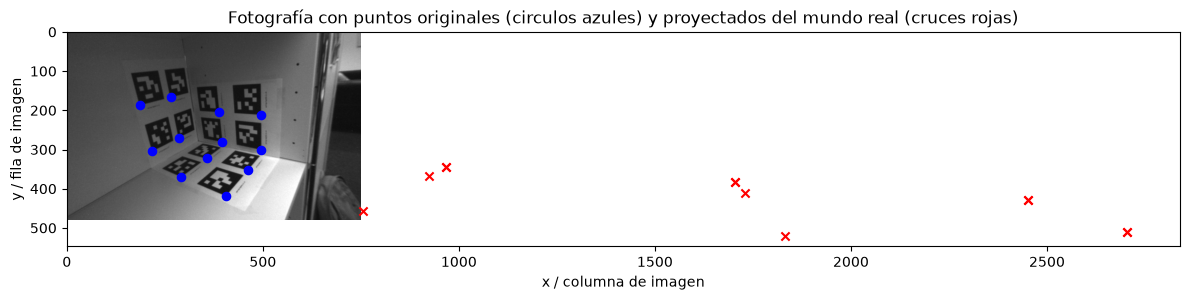

In [ ]:
figsize=(12, 8)

U, V = videoPts[0::2], videoPts[1::2]
X, Y = proj_img[0,:], proj_img[1,:]

marker_size=35
fig, ax = plt.subplots(figsize=figsize)

ax.imshow(img_rgb)
ax.scatter(U, V, s=marker_size, marker="o", color='blue')
ax.scatter(X, Y, s=marker_size, marker="x", color='red')

ax.set_title("Fotografía con puntos originales (circulos azules) y proyectados del mundo real (cruces rojas)")
ax.set_xlabel("x / columna de imagen")
ax.set_ylabel("y / fila de imagen")
ax.grid(False)
plt.tight_layout()

#grafica cualquier cosa porque H es la homografia de salguero 
